# Crazy Cylinder Data Analysis

### Libraries, constants and helper functions

In [18]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import curve_fit
from scipy.signal import lombscargle
from collections import defaultdict
from scipy.optimize import curve_fit as _curve_fit
from matplotlib.ticker import MaxNLocator

mpl.rcParams['font.family']  = 'serif'
mpl.rcParams['font.serif']   = ['Computer Modern Roman']
mpl.rcParams['text.usetex']  = True
mpl.rcParams['axes.grid']    = False

# base paths
BASE_EXP   = '../data/rawExp'
BASE_SWEEP = '../data/rawSim/sweep'
BASE_NN    = '../data/rawExp/nonewtonian'
BASE_NAT = '../data/rawSim/natFreq'

R = 0.011
D = 2 * R   
MU_STD     = 1.0
L_STD      = 0.6
FIT_RHOS = 1030
RHOS_FIG = 1030
MU_DW = '0.333333'
MU_RHOS = 1380
MU_L = 0.6
L_RHOS = 1380.0
L_MU   = 1.0

W = {
    'dw03':        0.066,
    'dw05':        0.044,
    'dw06':        0.033,
    'nonewtonian': 0.066,
    '0.5':         0.044,
    '0.333333':    0.066,
    '0.666667':    0.033,
}

dw_frac  = {'dw03': '1/3', 'dw05': '1/2', 'dw06': '2/3'}

mu_v_configs = {
    'v1': {'vin': 0.023, 'marker': '^', 'linestyle': ':', 'alpha': 0.4, 'facecolor': 'black'},
    'v3': {'vin': 0.078, 'marker': 's', 'linestyle': '--', 'alpha': 0.4, 'facecolor': 'black'},
    'v5': {'vin': 0.143, 'marker': 'o', 'linestyle': '-', 'alpha': 0.8, 'facecolor': 'white'},
}

nn_v_configs = {
    'v1': {'label': r'$V = 0.023$ m/s', 'marker': '^', 'facecolor': 'black', 'alpha': 0.4},
    'v5': {'label': r'$V = 0.143$ m/s', 'marker': 'o', 'facecolor': 'white', 'alpha': 0.8},
}

nn_ratios = {
    '000': {'x': 0.00, 'xerr': 0.000},
    '025': {'x': 0.25, 'xerr': 0.0025},
    '040': {'x': 0.40, 'xerr': 0.006},
}

l_plot_configs = {
    'v1': {'vin': 0.023, 'marker': 's'},
    'v3': {'vin': 0.078, 'marker': '^'},
}

NN_IMG = os.path.join(BASE_NN, 'nonnewtonian.png')

def read_exp(file_path):
    """
    Read a rawExp file (dw03, dw05 or nonewtonian).
    Returns t, x, y as float arrays.
    Handles comma decimals and skips non-numeric rows.
    """
    try:
        data = pd.read_csv(
            file_path, sep=r'\s+', decimal=',',
            header=None, skiprows=2,
            names=['t', 'x', 'y'], on_bad_lines='skip'
        )
    except Exception:
        data = pd.read_csv(
            file_path, sep=r'\s+', decimal='.',
            header=None, skiprows=2,
            names=['t', 'x', 'y'], on_bad_lines='skip'
        )
    data = data.apply(pd.to_numeric, errors='coerce').dropna()
    return data['t'].values, data['x'].values, data['y'].values


def read_sim(file_path):
    """
    Read a simulation output file.
    Returns the first three columns as t, x, vx.
    """
    data = pd.read_csv(
        file_path, sep=r'\s+', decimal='.',
        header=0, on_bad_lines='skip'
    )
    data = data.apply(pd.to_numeric, errors='coerce').dropna()
    cols = data.columns.tolist()
    return data[cols[0]].values, data[cols[1]].values, data[cols[2]].values


def compute_lombscargle(t, z, f_min=0.01, f_max=4.0, n_freq=1000):
#def compute_lombscargle(t, z, f_min=0.1, f_max=1.0, n_freq=1000):
    """
    Lomb-Scargle periodogram of z(t).
    Returns f_arr and power normalized to its maximum.
    """
    z_c   = z - np.mean(z)
    f_arr = np.linspace(f_min, f_max, n_freq)
    omega = 2 * np.pi * f_arr
    power = lombscargle(t, z_c, omega)
    power = power / np.max(power) if np.max(power) > 0 else power
    return f_arr, power

def linear(t, v, y0):
    return v * t + y0

def fit_velocity(t, y):
    (vy, y0), cov = curve_fit(linear, t, y)
    dvy = np.sqrt(np.diag(cov))[0]
    return vy, dvy, y0

def parse_sweep_filename(fname):
    """
    '0.333333_1380_0.023_1_0.6_4.txt'
    → {'dw', 'rhoS', 'vin', 'mulabel', 'l', 'm'}
    """
    base  = os.path.basename(fname).replace('.txt', '')
    parts = base.split('_')
    if len(parts) != 6: return None
    try:
        return {
            'dw':      parts[0],
            'rhoS':    float(parts[1]),
            'vin':     float(parts[2]),
            'mulabel': float(parts[3]),
            'l':       float(parts[4]),
            'm':       int(parts[5]),
        }
    except ValueError:
        return None

def peak_freq(t, vx):
    """Max peak between the LS of x and LS of vx."""
    _, Pvx = compute_lombscargle(t, vx)
    f_arr  = np.linspace(0.01, 4.0, 1000)
    return f_arr[np.argmax(Pvx)]

def _get_sim_individual(rhoS, dw_label, only_nominal=True):
    """List of (vin, freq) for every repetition file."""
    dw_num = dw_num_inv[dw_label]
    points = []
    for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
        info = parse_sweep_filename(fpath)
        if info is None:                                          continue
        if info['dw'] != dw_num:                                  continue
        if not np.isclose(info['rhoS'],    rhoS,    atol=0.5):   continue
        if not np.isclose(info['mulabel'], MU_STD,  atol=1e-6):  continue
        if not np.isclose(info['l'],       L_STD,   atol=1e-6):  continue
        if only_nominal and not any(np.isclose(info['vin'], v, atol=1e-4)
                                    for v in v_nom_set):          continue
        try:
            t, x, vx = read_sim(fpath)
            points.append((info['vin'], peak_freq(t, vx)))
        except Exception as e:
            print(f"  WARN {os.path.basename(fpath)}: {e}")
    return points

def _get_exp_individual(rhoS, dw_label):
    """List of (vel, freq) for every experimental repetition file."""
    folder = os.path.join(BASE_EXP, dw_label)
    dw_num = '03' if dw_label == 'dw03' else '05'
    c_key  = rhoS_to_c[rhoS]
    points = []
    for v_key in ['v1', 'v2', 'v3', 'v4', 'v5']:
        for m_key in ['m1', 'm2', 'm3', 'm4']:
            fname = f"{dw_num}{c_key}{v_key}{m_key}.txt"
            fpath = os.path.join(folder, fname)
            if not os.path.exists(fpath):
                continue
            try:
                t, x, y  = read_exp(fpath)
                vx       = np.gradient(x, t)
                vy, _, _ = fit_velocity(t, y)
                points.append((abs(vy), peak_freq(t, vx)))
            except Exception as e:
                print(f"  WARN {fname}: {e}")
    return points

def _get_sim_mu(vin):
    """
    Pull all mulabel values for fixed dw=1/3, rhoS=1380, l=0.6
    and the given vin from sim_freq.
    Returns mu_vals, freq_means, freq_stds sorted by mulabel.
    """
    rows = []
    for (kdw, krhoS, kvin, kmu, kl), val in sim_freq.items():
        if kdw != MU_DW:                                continue
        if not np.isclose(krhoS, MU_RHOS, atol=0.5):   continue
        if not np.isclose(kvin,  vin,     atol=1e-4):   continue
        if not np.isclose(kl,    MU_L,    atol=1e-6):   continue
        rows.append((kmu, val['mean'], val['std']))
    if not rows:
        return np.array([]), np.array([]), np.array([])
    rows.sort()
    return tuple(np.array([r[i] for r in rows]) for i in range(3))

def _get_sim_mu_individual(vin):
    """
    Pull every repetition file for fixed dw=1/3, rhoS=1380, l=0.6
    and the given vin. Returns list of (mulabel, freq).
    """
    points = []
    for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
        info = parse_sweep_filename(fpath)
        if info is None:                                             continue
        if info['dw'] != MU_DW:                                      continue
        if not np.isclose(info['rhoS'],    MU_RHOS, atol=0.5):       continue
        if not np.isclose(info['vin'],     vin,     atol=1e-4):       continue
        if not np.isclose(info['l'],       MU_L,    atol=1e-6):       continue
        try:
            t, x, vx = read_sim(fpath)
            points.append((info['mulabel'], peak_freq(t, vx)))
        except Exception as e:
            print(f"  WARN {os.path.basename(fpath)}: {e}")
    return points

def _get_nn_individual(v_key):
    """Pull (x_ratio, freq) for every repetition file."""
    points = []
    for code, cfg in nn_ratios.items():
        for m_key in ['m1', 'm2', 'm3', 'm4']:
            fname = f"{code}{v_key}{m_key}.txt"
            fpath = os.path.join(BASE_NN, fname)
            if not os.path.exists(fpath):
                continue
            try:
                t, x, y = read_exp(fpath)
                vx      = np.gradient(x, t)
                points.append((cfg['x'], peak_freq(t, vx)))
            except Exception as e:
                print(f"  WARN {fname}: {e}")
    return points

def _panel_mu(ax):
    """f/f_n vs mu/mu_0: every repetition plus a line through the means."""
    fn = nat_freq[(MU_DW, MU_RHOS)]['mean']

    for cfg in mu_v_configs.values():
        mu_arr, fmeans, _ = _get_sim_mu(cfg['vin'])
        if len(mu_arr):
            ax.plot(mu_arr, fmeans / fn, linestyle=cfg['linestyle'],
                    color='black', lw=1.2, zorder=2)

        pts = _get_sim_mu_individual(cfg['vin'])
        if pts:
            mu_v, f_v = np.array(pts).T
            ax.scatter(mu_v, f_v / fn,
                       marker=cfg['marker'], color='black', s=POINT_SIZE,
                       alpha=cfg['alpha'], facecolor=cfg['facecolor'],
                       linewidths=1.5, zorder=3)

    ax.set_xscale('log')
    ax.set_xlabel(r'$\mu/\mu_0$', fontsize=FONT_SIZE)
    ax.set_ylabel(r'$f/f_n$',     fontsize=FONT_SIZE)

def _panel_nn(ax):
    """f/f_n vs m_C/m_T: every repetition."""
    fn = nat_freq[(MU_DW, MU_RHOS)]['mean']

    for v_key, cfg in nn_v_configs.items():
        pts = _get_nn_individual(v_key)
        if not pts:
            continue
        x_v, f_v = np.array(pts).T
        ax.scatter(x_v, f_v / fn,
                   marker=cfg['marker'], color='black', s=POINT_SIZE,
                   alpha=0.6, facecolors=cfg['facecolor'])

    ax.set_xlabel(r'$m_C/m_T$', fontsize=FONT_SIZE)
    ax.set_ylabel(r'$f/f_n$',   fontsize=FONT_SIZE)


def _get_sim_l_dw(dw_str, vin):
    """l, freq_mean, freq_std from sim_freq at a given dw, vin (rhoS=1380, mulabel=1)."""
    rows = []
    for (kdw, krhoS, kvin, kmu, kl), val in sim_freq.items():
        if kdw != dw_str:                              continue
        if not np.isclose(krhoS, L_RHOS, atol=0.5):    continue
        if not np.isclose(kvin,  vin,    atol=1e-4):   continue
        if not np.isclose(kmu,   L_MU,   atol=1e-6):   continue
        rows.append((kl, val['mean'], val['std']))
    if not rows:
        return np.array([]), np.array([]), np.array([])
    rows.sort()
    return tuple(np.array([r[i] for r in rows]) for i in range(3))


def _panel_l(ax, dw_str):
    fn = nat_freq[(dw_str, L_RHOS)]['mean']
    for cfg in l_plot_configs.values():
        l_v, f_m, f_s = _get_sim_l_dw(dw_str, cfg['vin'])
        if len(l_v) == 0:
            continue
        ax.errorbar(l_v, f_m/fn, yerr=f_s/fn,
                    fmt=cfg['marker'], color='black', capsize=4,
                    lw=1.5, ms=8, alpha=0.8, zorder=3)

    ax.set_xlabel(r'$l$ [m]',  fontsize=FONT_SIZE)
    ax.set_ylabel(r'$f/f_n$', fontsize=FONT_SIZE)
    ax.tick_params(axis='both', which='major', labelsize=TICK_SIZE)


### Compute frequencies

In [10]:
exp_freq = {}
nn_freq  = {}

# ── Cylinder / confinement mappings ───────────────────────────
rhoS_to_c   = {1030: 'c1', 1380: 'c6'}
c_to_rhoS   = {'c1': 1030, 'c6': 1380}
dw_to_label = {'0.5': 'dw05', '0.333333': 'dw03', '0.666667': 'dw06'}

# ── dw03 and dw05 ─────────────────────────────────────────────
for dw_label in ['dw03', 'dw05']:
    folder = os.path.join(BASE_EXP, dw_label)
    dw_num = '03' if dw_label == 'dw03' else '05'

    for rhoS, c_key in sorted(rhoS_to_c.items()):
        for v_key in ['v1', 'v2', 'v3', 'v4', 'v5']:
            freqs_m = []
            vels_m  = []
            for m_key in ['m1', 'm2', 'm3', 'm4']:
                fname = f"{dw_num}{c_key}{v_key}{m_key}.txt"
                fpath = os.path.join(folder, fname)
                if not os.path.exists(fpath):
                    continue
                try:
                    t, x, y  = read_exp(fpath)
                    vx       = np.gradient(x, t)
                    vy, _, _ = fit_velocity(t, y)
                    freqs_m.append(peak_freq(t, vx))
                    vels_m.append(abs(vy))
                except Exception as e:
                    print(f"  WARN {fname}: {e}")

            if freqs_m:
                exp_freq[(dw_label, rhoS, v_key)] = {
                    'freq_mean': np.mean(freqs_m),
                    'freq_std':  np.std(freqs_m),
                    'vel_mean':  np.mean(vels_m),
                    'vel_std':   np.std(vels_m),
                    'n':         len(freqs_m),
                }

print(f"exp_freq: {len(exp_freq)} entries computed")

for ratio_code in ['000', '025', '040']:
    for v_key in ['v1', 'v5']:
        freqs_m = []
        for m_key in ['m1', 'm2', 'm3', 'm4']:
            fname = f"{ratio_code}{v_key}{m_key}.txt"
            fpath = os.path.join(BASE_NN, fname)
            if not os.path.exists(fpath):
                continue
            try:
                t, x, y = read_exp(fpath)
                vx      = np.gradient(x, t)
                freqs_m.append(peak_freq(t, vx))
            except Exception as e:
                print(f"  WARN {fname}: {e}")

        if freqs_m:
            nn_freq[(ratio_code, v_key)] = {
                'mean': np.mean(freqs_m),
                'std':  np.std(freqs_m),
                'n':    len(freqs_m),
            }

print(f"nn_freq:  {len(nn_freq)} entries computed")

sim_freq = {}

# group repetitions by config key
_groups = defaultdict(list)

for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
    info = parse_sweep_filename(fpath)
    if info is None:
        print(f"  WARN skip: {os.path.basename(fpath)}")
        continue
    key = (info['dw'], info['rhoS'], info['vin'], info['mulabel'], info['l'])
    try:
        t, x, vx = read_sim(fpath)
        f        = peak_freq(t, vx)
        _groups[key].append(f)
    except Exception as e:
        print(f"  WARN {os.path.basename(fpath)}: {e}")

for key, freqs in _groups.items():
    mean, std, n_used = np.mean(freqs), np.std(freqs), len(freqs)
    sim_freq[key] = {
        'mean':    mean,
        'std':     std,
        'n':       n_used,
        'n_total': len(freqs),   # total repetitions found before trimming
    }

print(f"sim_freq: {len(sim_freq)} configurations computed")


exp_freq: 10 entries computed
nn_freq:  6 entries computed
sim_freq: 126 configurations computed


### Compute lock-out reduced velocities

In [4]:
sim_amp    = {}
lock_out_v = {}
dw_num_inv = {'dw05': '0.5', 'dw03': '0.333333', 'dw06': '0.666667'}

for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
    info = parse_sweep_filename(fpath)
    if info is None:
        continue
    key   = (info['dw'], info['rhoS'], info['vin'],
              info['mulabel'], info['l'], info['m'])
    w_val = D / float(info['dw'])
    try:
        _, x, _ = read_sim(fpath)
        sim_amp[key] = np.max(np.abs(x - w_val / 2))
    except Exception as e:
        print(f"  WARN {os.path.basename(fpath)}: {e}")

print(f"sim_amp: {len(sim_amp)} repetitions computed")

# ── End-of-lock-in per confinement ────────────────────────────
for dw_label in ['dw05', 'dw03', 'dw06']:
    dw_num = dw_num_inv[dw_label]

    v_amps = defaultdict(list)
    for (kdw, krhoS, kvin, kmu, kl, km), amp in sim_amp.items():
        if kdw != dw_num:                              continue
        if not np.isclose(krhoS, 1030,    atol=0.5):  continue
        if not np.isclose(kmu,   MU_STD,  atol=1e-6): continue
        if not np.isclose(kl,    L_STD,   atol=1e-6): continue
        v_amps[kvin].append(amp)

    if len(v_amps) < 2:
        continue

    vins_sorted = sorted(v_amps.keys())
    lock_found  = False

    for i in range(len(vins_sorted) - 1):
        v_lo      = vins_sorted[i]
        v_hi      = vins_sorted[i + 1]
        max_lo    = max(v_amps[v_lo])
        min_hi    = min(v_amps[v_hi])

        if min_hi < max_lo / 2:
            lock_out_v[dw_label] = (v_lo + v_hi) / 2
            print(f"  {dw_label}: first drop below half at "
                  f"V={v_lo:.3f} → V={v_hi:.3f} m/s  "
                  f"(max_lo={max_lo*1000:.2f} mm, min_hi={min_hi*1000:.2f} mm)  "
                  f"→ lock-out at V={lock_out_v[dw_label]:.4f} m/s")
            lock_found = True
            break

    if not lock_found:
        print(f"  {dw_label}: no lock-out detected")

sim_amp: 504 repetitions computed
  dw05: first drop below half at V=0.050 → V=0.056 m/s  (max_lo=10.53 mm, min_hi=2.48 mm)  → lock-out at V=0.0530 m/s
  dw03: first drop below half at V=0.078 → V=0.083 m/s  (max_lo=20.97 mm, min_hi=4.33 mm)  → lock-out at V=0.0805 m/s
  dw06: first drop below half at V=0.029 → V=0.034 m/s  (max_lo=5.40 mm, min_hi=0.38 mm)  → lock-out at V=0.0315 m/s


### Compute natural frequencies

In [5]:
def parse_natfreq_filename(fname):
    """'{dw}_{rhoS}_0_{displacement}.txt' → {'dw', 'rhoS', 'displacement'}"""
    base  = os.path.basename(fname).replace('.txt', '')
    parts = base.split('_')
    if len(parts) != 4:
        return None
    try:
        return {
            'dw':           parts[0],
            'rhoS':         float(parts[1]),
            'displacement': float(parts[3]),
        }
    except ValueError:
        return None

# group by (dw, rhoS)
_nat_groups = defaultdict(list)

for fpath in sorted(glob.glob(os.path.join(BASE_NAT, '*.txt'))):
    info = parse_natfreq_filename(fpath)
    if info is None:
        print(f"  WARN skip: {os.path.basename(fpath)}")
        continue
    try:
        t, x, vx = read_sim(fpath)
        f         = peak_freq(t, vx)
        _nat_groups[(info['dw'], info['rhoS'])].append(f)
    except Exception as e:
        print(f"  WARN {os.path.basename(fpath)}: {e}")

# nat_freq[(dw_str, rhoS)] = {'mean', 'std', 'n'}
nat_freq = {}
for (dw_str, rhoS), freqs in sorted(_nat_groups.items()):
    nat_freq[(dw_str, rhoS)] = {
        'mean': np.mean(freqs),
        'std':  np.std(freqs),
        'n':    len(freqs),
    }

# ── Print table ───────────────────────────────────────────────
dw_label_map = {'0.5': 'D/W=1/2', '0.333333': 'D/W=1/3', '0.666667': 'D/W=2/3'}

header = f"{'D/W':<12} {'rhoS':>8}   {'f_n [Hz]':>18}   {'n':>4}"
print(header)
print('-' * len(header))
for (dw_str, rhoS), v in sorted(nat_freq.items()):
    label = dw_label_map.get(dw_str, dw_str)
    print(f"{label:<12} {rhoS:>8.0f}   "
          f"{v['mean']:>8.4f} ± {v['std']:>7.4f} Hz   {v['n']:>4}")

D/W              rhoS             f_n [Hz]      n
-------------------------------------------------
D/W=1/3          1030     0.1977 ±  0.0224 Hz      4
D/W=1/3          1380     0.2307 ±  0.0192 Hz      4
D/W=1/2          1030     0.2227 ±  0.0052 Hz      4
D/W=1/2          1380     0.2556 ±  0.0060 Hz      4
D/W=2/3          1030     0.2596 ±  0.0060 Hz      4
D/W=2/3          1380     0.2936 ±  0.0075 Hz      4


### Table 1

In [6]:
print(f"{'D/W':<6} {'St':>6} {'R^2':>6} {'St*':>6} {'n':>4}")
print('-' * 32)

for dw_label in ['dw03', 'dw05', 'dw06']:
    W_val = W[dw_label]
    fn    = nat_freq[(dw_num_inv[dw_label], FIT_RHOS)]['mean']

    # every repetition; dw06 has no experimental data
    pts = _get_sim_individual(FIT_RHOS, dw_label, only_nominal=False)
    if dw_label != 'dw06':
        pts += _get_exp_individual(FIT_RHOS, dw_label)

    V, f = np.array(pts).T

    # keep only V_r < 5 or f/f_n > 4
    mask = (V / (fn * D) < 5) | (f / fn > 4)
    V, f = V[mask], f[mask]

    # least-squares slope of f = (St / D) V through the origin
    St     = D * np.sum(V * f) / np.sum(V**2)
    R2     = 1 - np.sum((f - St * V / D)**2) / np.sum((f - f.mean())**2)
    St_star = St * (1 - D / W_val)

    print(f"{dw_frac[dw_label]:<6} {St:>6.2f} {R2:>6.2f} {St_star:>6.2f} {len(V):>4}")

D/W        St    R^2    St*    n
--------------------------------
1/3      0.22   0.94   0.15   72
1/2      0.35   0.95   0.18   91
2/3      0.56   0.73   0.19   47


### Figure 2

  dw03: St=0.224  St*=0.149  R²=0.938
  dw05: St=0.353  St*=0.176  R²=0.951
  dw06: St=0.565  St*=0.188  R²=0.732


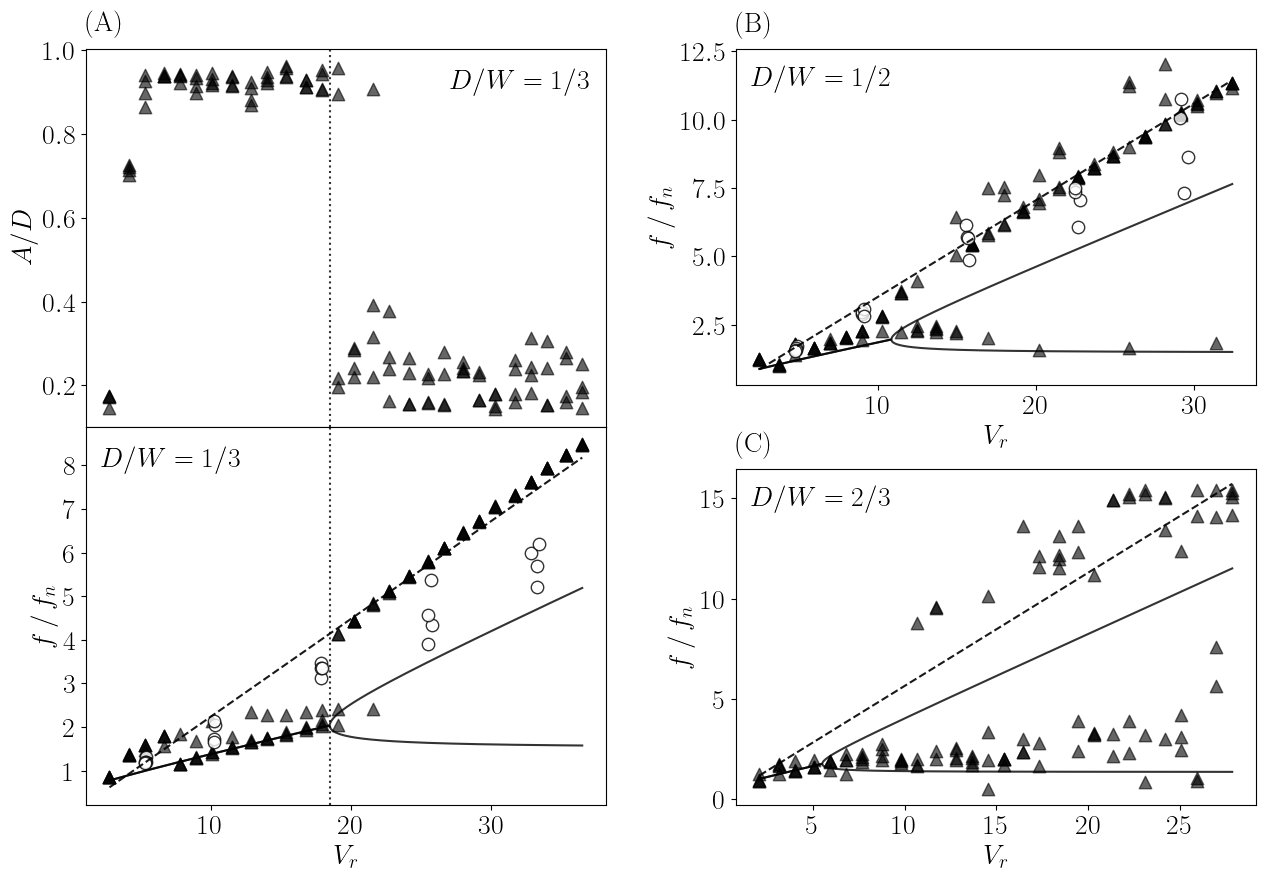

In [7]:
FONT_SIZE = 20   # axis labels, text boxes, panel letters
TICK_SIZE = 20   # tick labels
POINT_SIZE = 80  # scatter points

def _get_sim_amp(rhoS, dw_label):
    dw_num = dw_num_inv[dw_label]
    rows   = []
    for (kdw, krhoS, kvin, kmu, kl, km), amp in sim_amp.items():
        if kdw != dw_num:                              continue
        if not np.isclose(krhoS, rhoS,    atol=0.5):  continue
        if not np.isclose(kmu,   MU_STD,  atol=1e-6): continue
        if not np.isclose(kl,    L_STD,   atol=1e-6): continue
        rows.append((kvin, amp))
    if not rows:
        return np.array([]), np.array([])
    rows.sort()
    return tuple(np.array([r[i] for r in rows]) for i in range(2))

def _solve_delangre(Vr, St, Vr_lo):
    """
    Solves de Langre (2006) linear coupled-mode flutter equation:
        w^4 + [(AM - 1)*Omega^2 - 1]*w^2 + Omega^2 = 0
    where Omega = St * Vr, returning real frequency branches (f / f_n).
    """
    AM = (1-1/(St * Vr_lo))**2
    
    Omega = St * Vr
    b = (1.0 - AM) * (Omega**2) + 1.0  # -B term
    disc = b**2 - 4.0 * (Omega**2)
    

    w_R1 = np.zeros_like(Vr)
    w_R2 = np.zeros_like(Vr)
    
    # Outside lock-in (disc >= 0): two distinct real branches
    mask_real = disc >= 0
    if np.any(mask_real):
        b_m = b[mask_real]
        d_m = np.sqrt(disc[mask_real])
        w2_plus  = (b_m + d_m) / 2.0
        w2_minus = (b_m - d_m) / 2.0
        w_R1[mask_real] = np.sqrt(np.maximum(0, w2_plus))
        w_R2[mask_real] = np.sqrt(np.maximum(0, w2_minus))
        
    # Inside lock-in (disc < 0): merged CMF branch
    mask_cmf = disc < 0
    if np.any(mask_cmf):
        w_cmf = np.sqrt((Omega[mask_cmf] + b[mask_cmf] / 2.0) / 2.0)
        w_R1[mask_cmf] = w_cmf
        w_R2[mask_cmf] = w_cmf
        
    return w_R1, w_R2, AM

def _panel_amp(ax, dw_label):
    """A/D vs V_r, every repetition, with lock-out line."""
    fn = nat_freq[(dw_num_inv[dw_label], RHOS_FIG)]['mean']
    vins, amps = _get_sim_amp(RHOS_FIG, dw_label)

    ax.scatter(vins / (fn * D), amps / D,
               marker='^', color='black', s=POINT_SIZE, alpha=0.6, zorder=3)
    ax.axvline(lock_out_v[dw_label] / (fn * D),
               color='black', ls=':', lw=1.5, alpha=0.8)
    ax.set_ylabel(r'$A/D$', fontsize=FONT_SIZE)


def _panel_freq(ax, dw_label, analytic=True, delangre=True, lock_line=False):
    """f/f_n vs V_r, every repetition (sim + exp), fit and de Langre curves."""
    W_val = W[dw_label]
    fn    = nat_freq[(dw_num_inv[dw_label], RHOS_FIG)]['mean']

    # simulation (all velocities) and experiment (no data for dw06)
    sim_pts = _get_sim_individual(RHOS_FIG, dw_label, only_nominal=False)
    vs, fs  = np.array(sim_pts).T
    ax.scatter(vs / (fn * D), fs / fn,
               marker='^', color='black', s=POINT_SIZE, alpha=0.6)
    V_all, f_all = list(vs), list(fs)

    if dw_label != 'dw06':
        exp_pts = _get_exp_individual(RHOS_FIG, dw_label)
        ve, fe  = np.array(exp_pts).T
        ax.scatter(ve / (fn * D), fe / fn,
                   marker='o', facecolors='white', color='black',
                   s=POINT_SIZE, alpha=0.8)
        V_all += list(ve); f_all += list(fe)

    V_all, f_all = np.array(V_all), np.array(f_all)
    V_grid  = np.linspace(V_all.min(), V_all.max(), 500)
    Vr_grid = V_grid / (fn * D)

    # uncoupled solution: least-squares line f = St V / D (V_r < 5 or f/f_n > 4)
    St = None
    if analytic:
        m  = (V_all / (fn * D) < 5) | (f_all / fn > 4)
        V, f = V_all[m], f_all[m]
        St = D * np.sum(V * f) / np.sum(V**2)
        R2 = 1 - np.sum((f - St * V / D)**2) / np.sum((f - f.mean())**2)
        print(f"  {dw_label}: St={St:.3f}  St*={St*(1-D/W_val):.3f}  R²={R2:.3f}")
        ax.plot(Vr_grid, (St * V_grid / D) / fn,
                color='black', ls='--', lw=1.5, alpha=0.9)

    # coupled-mode curves (de Langre), uses the fitted St
    if delangre and St is not None:
        Vr_lo = lock_out_v[dw_label] / (fn * D)
        w1, w2, _ = _solve_delangre(Vr_grid, St=St, Vr_lo=Vr_lo)
        ax.plot(Vr_grid, w1, color='black', ls='-', lw=1.5, alpha=0.8)
        ax.plot(Vr_grid, w2, color='black', ls='-', lw=1.5, alpha=0.8)

    if lock_line:
        ax.axvline(lock_out_v[dw_label] / (fn * D),
                   color='black', ls=':', lw=1.5, alpha=0.8)

    ax.set_xlabel(r'$V_r$', fontsize=FONT_SIZE)
    ax.set_ylabel(r'$f\,/\,f_n$', fontsize=FONT_SIZE)


def plot_main_figure(analytic=True, delangre=True, show=True,
                     base_figures='../figures'):

    fig   = plt.figure(figsize=(13, 9))
    outer = fig.add_gridspec(1, 2, wspace=0.25)
    left  = outer[0].subgridspec(2, 1, hspace=0)      # glued together
    right = outer[1].subgridspec(2, 1, hspace=0.25)   # normal spacing

    ax_A = fig.add_subplot(left[0])
    ax_L = fig.add_subplot(left[1], sharex=ax_A)
    ax_B = fig.add_subplot(right[0])
    ax_C = fig.add_subplot(right[1])

    # ── panels ────────────────────────────────────────────────
    _panel_amp(ax_A, 'dw03')                                             # top left
    _panel_freq(ax_L, 'dw03', analytic, delangre, lock_line=True)        # bottom left
    _panel_freq(ax_B, 'dw05', analytic, delangre)                        # top right
    _panel_freq(ax_C, 'dw06', analytic, delangre)                        # bottom right

    ax_A.tick_params(labelbottom=False)   # no x axis on top-left panel

    # drop the top y tick of the bottom-left panel so its label
    # doesn't collide with the bottom label of the panel above
    ax_L.yaxis.set_major_locator(MaxNLocator(prune='upper'))

    # ── text boxes inside the graphs ──────────────────────────
    def box(ax, txt, x, ha):
        ax.text(x, 0.95, txt, transform=ax.transAxes,
                fontsize=FONT_SIZE, ha=ha, va='top')

    box(ax_A, r'$D/W=1/3$', 0.97, 'right')
    box(ax_L, r'$D/W=1/3$', 0.03, 'left')
    box(ax_B, r'$D/W=1/2$', 0.03, 'left')
    box(ax_C, r'$D/W=2/3$', 0.03, 'left')

    # ── bold panel letters outside, top-left corner ───────────
    for ax, letter in [(ax_A, '(A)'), (ax_B, '(B)'), (ax_C, '(C)')]:
        ax.text(0.0, 1.03, letter, transform=ax.transAxes,
                fontsize=FONT_SIZE, fontweight='bold', ha='left', va='bottom')

    for ax in (ax_A, ax_L, ax_B, ax_C):
        ax.tick_params(axis='both', which='major', labelsize=TICK_SIZE)

    fig.subplots_adjust(left=0.08, right=0.98, top=0.93, bottom=0.09)

    if show:
        plt.show()
    else:
        out_path = os.path.join(base_figures, 'fig2.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")

# ── Calls ─────────────────────────────────────────────────────
plot_main_figure(show=True)
# plot_main_figure(show=False)

### Figure 3

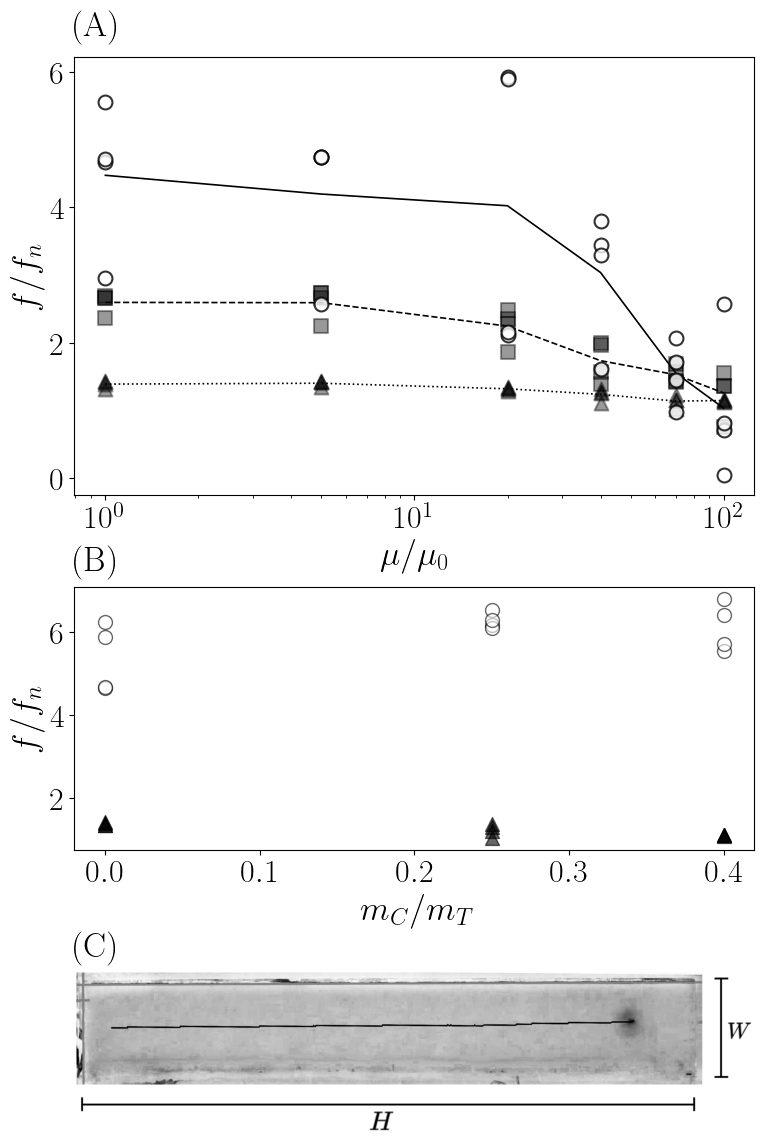

In [11]:
FONT_SIZE = 25   # axis labels, text boxes, panel letters
TICK_SIZE = 23   # tick labels
POINT_SIZE = 100  # scatter points

def plot_viscous_figure(show=True, base_figures='../figures'):

    fig, (ax_A, ax_B, ax_C) = plt.subplots(
        3, 1, figsize=(8, 12),
        gridspec_kw={'height_ratios': [1, 0.6, 0.5], 'hspace': 0.3})

    _panel_mu(ax_A)
    _panel_nn(ax_B)

    # bottom panel: image only
    ax_C.imshow(plt.imread(NN_IMG))
    ax_C.axis('off')

    for ax in (ax_A, ax_B):
        ax.tick_params(axis='both', which='major', labelsize=TICK_SIZE)

    # bold panel letters outside, top-left corner
    for ax, letter in [(ax_A, '(A)'), (ax_B, '(B)'), (ax_C, '(C)')]:
        ax.text(0.0, 1.03, letter, transform=ax.transAxes,
                fontsize=FONT_SIZE, fontweight='bold', ha='left', va='bottom')

    fig.subplots_adjust(left=0.12, right=0.97, top=0.96, bottom=0.04)

    if show:
        plt.show()
    else:
        out_path = os.path.join(base_figures, 'fig3.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


# ── Calls ─────────────────────────────────────────────────────
plot_viscous_figure(show=True)

### l sensitivity

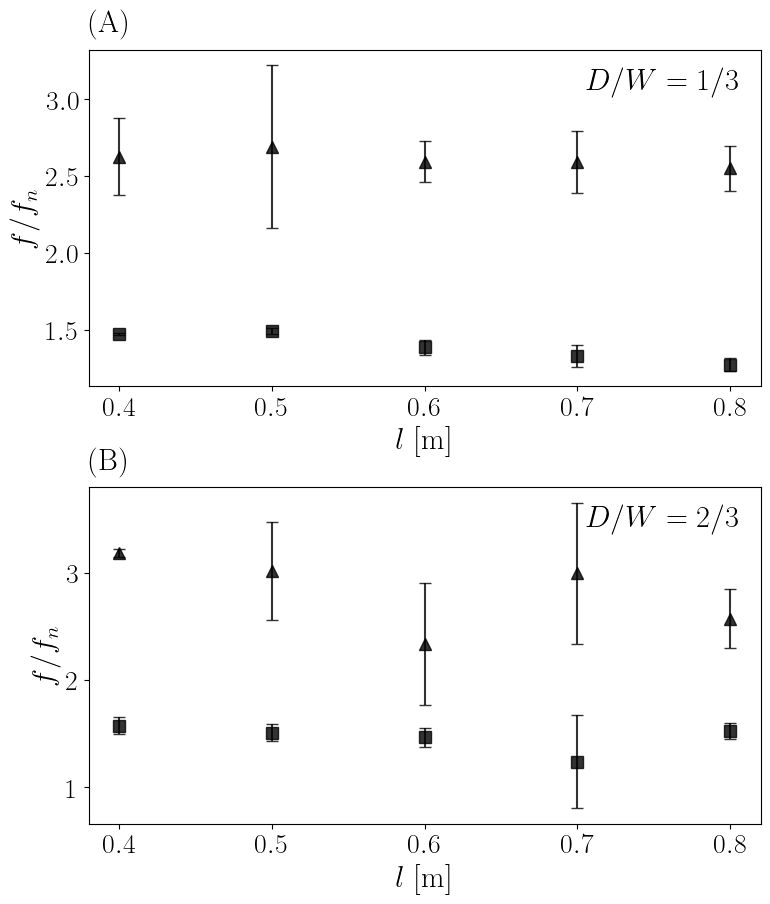

In [17]:
FONT_SIZE = 22   # axis labels, text boxes, panel letters
TICK_SIZE = 20   # tick labels
POINT_SIZE = 80  # scatter points

def plot_l_figure(show=True, base_figures='../figures'):

    fig, (ax_A, ax_B) = plt.subplots(2, 1, figsize=(8, 9),
                                     gridspec_kw={'hspace': 0.3})

    _panel_l(ax_A, '0.333333')
    _panel_l(ax_B, '0.666667')

    # text boxes inside the graphs, top right
    for ax, txt in [(ax_A, r'$D/W=1/3$'), (ax_B, r'$D/W=2/3$')]:
        ax.text(0.97, 0.95, txt, transform=ax.transAxes,
                fontsize=FONT_SIZE, ha='right', va='top')

    # bold panel letters outside, top-left corner
    for ax, letter in [(ax_A, '(A)'), (ax_B, '(B)')]:
        ax.text(0.0, 1.03, letter, transform=ax.transAxes,
                fontsize=FONT_SIZE, fontweight='bold', ha='left', va='bottom')

    fig.subplots_adjust(left=0.13, right=0.97, top=0.94, bottom=0.08)

    if show:
        plt.show()
    else:
        out_path = os.path.join(base_figures, 'l_sensitivity.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


# ── Calls ─────────────────────────────────────────────────────
plot_l_figure(show=True)